In [58]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid', context='notebook')

df = pd.read_csv('akc-data-latest.csv')
df_raw = df.copy()

df = df.rename(columns={'Unnamed: 0': 'breed'})

# строки преобразуем в числа
df['popularity'] = pd.to_numeric(df['popularity'], errors='coerce')


TEXT_COLS = ['description', 'temperament']


print('df:              ', df.shape)
print('NaN в popularity:', df['popularity'].isna().sum(),
      f"({df['popularity'].isna().mean():.1%})")
print('Диапазон popularity:', df['popularity'].min(), '—', df['popularity'].max())

preview_cols = [
    'breed', 'group', 'popularity',
    'min_height', 'max_height', 'min_weight', 'max_weight',
    'min_expectancy', 'max_expectancy',
    'energy_level_value', 'trainability_value', 'demeanor_value',
    'grooming_frequency_value', 'shedding_value',
]
df[preview_cols].head(5)

df:               (277, 21)
NaN в popularity: 82 (29.6%)
Диапазон popularity: 1.0 — 192.0


,breed,group,popularity,min_height,max_height,min_weight,max_weight,min_expectancy,max_expectancy,energy_level_value,trainability_value,demeanor_value,grooming_frequency_value,shedding_value
0,Affenpinscher,Toy Group,148.0,22.86,29.21,3.175147,4.535924,12.0,15.0,0.6,0.8,1.0,0.6,0.6
1,Afghan Hound,Hound Group,113.0,63.50,68.58,22.679619,27.215542,12.0,15.0,0.8,0.2,0.2,0.8,0.2
2,Airedale Terrier,Terrier Group,60.0,58.42,58.42,22.679619,31.751466,11.0,14.0,0.6,1.0,0.8,0.6,0.4
3,Akita,Working Group,47.0,60.96,71.12,31.751466,58.967008,10.0,13.0,0.8,1.0,0.6,0.8,0.6
4,Alaskan Malamute,Working Group,58.0,58.42,63.50,34.019428,38.555351,10.0,14.0,0.8,0.4,0.8,0.6,0.6


In [59]:
TEXT_COLS = ['description', 'temperament']
cols_19 = [c for c in df.columns if c not in TEXT_COLS]

print('Столбцов в выводе:', len(cols_19))
print(cols_19)
print()
df[cols_19].head(5)

Столбцов в выводе: 19
['breed', 'popularity', 'min_height', 'max_height', 'min_weight', 'max_weight', 'min_expectancy', 'max_expectancy', 'group', 'grooming_frequency_value', 'grooming_frequency_category', 'shedding_value', 'shedding_category', 'energy_level_value', 'energy_level_category', 'trainability_value', 'trainability_category', 'demeanor_value', 'demeanor_category']



,breed,popularity,min_height,max_height,min_weight,max_weight,min_expectancy,max_expectancy,group,grooming_frequency_value,grooming_frequency_category,shedding_value,shedding_category,energy_level_value,energy_level_category,trainability_value,trainability_category,demeanor_value,demeanor_category
0,Affenpinscher,148.0,22.86,29.21,3.175147,4.535924,12.0,15.0,Toy Group,0.6,2-3 Times a Week Brushing,0.6,Seasonal,0.6,Regular Exercise,0.8,Easy Training,1.0,Outgoing
1,Afghan Hound,113.0,63.50,68.58,22.679619,27.215542,12.0,15.0,Hound Group,0.8,Daily Brushing,0.2,Infrequent,0.8,Energetic,0.2,May be Stubborn,0.2,Aloof/Wary
2,Airedale Terrier,60.0,58.42,58.42,22.679619,31.751466,11.0,14.0,Terrier Group,0.6,2-3 Times a Week Brushing,0.4,Occasional,0.6,Regular Exercise,1.0,Eager to Please,0.8,Friendly
3,Akita,47.0,60.96,71.12,31.751466,58.967008,10.0,13.0,Working Group,0.8,Daily Brushing,0.6,Seasonal,0.8,Energetic,1.0,Eager to Please,0.6,Alert/Responsive
4,Alaskan Malamute,58.0,58.42,63.50,34.019428,38.555351,10.0,14.0,Working Group,0.6,2-3 Times a Week Brushing,0.6,Seasonal,0.8,Energetic,0.4,Independent,0.8,Friendly


In [60]:
# исследуем связь нан в popularity c породой
pop_by_group = (df.assign(has_rank=df['popularity'].notna())
                  .groupby('group')['has_rank']
                  .agg(n='size', n_ranked='sum')
                  .assign(pct_nan=lambda x: (1 - x['n_ranked']/x['n']).round(3))
                  .sort_values('pct_nan', ascending=False))
print(pop_by_group.to_string())

# хи-квадрат и тсатистика Крамера
ct = pd.crosstab(df['group'], df['popularity'].notna())
chi2, p, dof, expected = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f'\nchi2={chi2:.2f}, p={p:.3g}, dof={dof}, V={cramers_v:.3f}')

# считаем одинаковые места
ranked = df['popularity'].dropna()
print(f'Ranked: {len(ranked)}, unique ranks: {ranked.nunique()}, '
      f'ties: {(ranked.value_counts() > 1).sum()} positions')





ct.columns = ['Нет ранга', 'Есть ранг']
ct['Всего пород'] = ct.sum(axis=1)
print('Таблица сопряженности')
print(ct.to_string())

                           n  n_ranked  pct_nan
group                                          
Foundation Stock Service  68         0    1.000
Miscellaneous Class       11         0    1.000
Working Group             31        30    0.032
Sporting Group            32        31    0.031
Hound Group               32        31    0.031
Non-Sporting Group        21        21    0.000
Herding Group             30        30    0.000
Terrier Group             31        31    0.000
Toy Group                 21        21    0.000

chi2=263.06, p=2.93e-52, dof=8, V=0.975
Ranked: 195, unique ranks: 190, ties: 4 positions
Таблица сопряженности
                          Нет ранга  Есть ранг  Всего пород
group                                                      
Foundation Stock Service         68          0           68
Herding Group                     0         30           30
Hound Group                       1         31           32
Miscellaneous Class              11          0           11

Статистически: связь между группой и наличием ранга почти детерминирована (V = 0.975). Это соответствует правилам AKC, по которым FSS и Miscellaneous не участвуют в рейтинге популярности

### Проверка механизма пропусков в popularity

**Гипотеза H₀:** факт наличия ранга популярности не зависит от породы.
**Гипотеза H₁:** факт наличия ранга связан с породой.

**Тест:** критерий независимости χ² для таблицы сопряжённости 9×2
(9 породных групп × «есть ранг / нет ранга»).

**Формула статистики:**

$$\chi^2 = \sum_{i,j} \frac{(O_{ij} - E_{ij})^2}{E_{ij}}, \qquad E_{ij} = \frac{R_i \cdot C_j}{n}$$

где $O_{ij}$ — наблюдаемая частота, $E_{ij}$ — ожидаемая при независимости,
$R_i$, $C_j$ — суммы по строке и столбцу, $n$ — общий размер.

**Размер эффекта — V Крамера** (не зависит от n и размера таблицы):

$$V = \sqrt{\frac{\chi^2}{n \cdot (\min(r, c) - 1)}}$$


**Интерпретация:**
- p ≪ 0.05, H₀ отвергается: наличие ранга связано с группой.
- V = 0.975 сильная связь.
- 100% пород FSS (n=68) и Miscellaneous (n=11) без ранга; в остальных
  7 группах без ранга лишь 3 из 198 (1.5%).
- **Вывод:** пропуски детерминированы правилом AKC
  (FSS и Miscellaneous не участвуют в рейтинге популярности).

In [61]:
for col in ['min_weight', 'max_weight', 'min_expectancy', 'max_expectancy']:
    print(f'{col:15s}: нулей = {(df[col] == 0).sum()}, NaN = {df[col].isna().sum()}')

min_weight     : нулей = 1, NaN = 2
max_weight     : нулей = 1, NaN = 2
min_expectancy : нулей = 1, NaN = 3
max_expectancy : нулей = 1, NaN = 3


In [62]:
# те, кто даёт нули
mask = (df[['min_weight','max_weight','min_expectancy','max_expectancy']] == 0).any(axis=1)
print(df.loc[mask, ['breed', 'group', 'min_weight', 'max_weight',
                    'min_expectancy', 'max_expectancy']].to_string(index=False))

            breed         group  min_weight  max_weight  min_expectancy  max_expectancy
       Cane Corso Working Group    0.000000    0.000000             9.0            12.0
Pyrenean Shepherd Herding Group    6.803886   13.607771             0.0             0.0


In [63]:
# те, кто даёт нан
mask_nan = df[['min_weight','max_weight','min_expectancy','max_expectancy']].isna().any(axis=1)
print(df.loc[mask_nan, ['breed', 'group', 'min_weight', 'max_weight',
                        'min_expectancy', 'max_expectancy']].to_string(index=False))

                     breed                    group  min_weight  max_weight  min_expectancy  max_expectancy
         Australian Kelpie Foundation Stock Service         NaN         NaN            10.0            13.0
  Braque Francais Pyrenean Foundation Stock Service   18.143695   24.947580             NaN             NaN
              Carolina Dog Foundation Stock Service   13.607771   24.947580             NaN             NaN
Central Asian Shepherd Dog Foundation Stock Service   39.916129   49.895161             NaN             NaN
          Spinone Italiano           Sporting Group         NaN         NaN            10.0            12.0


In [64]:
# Заменяем 0 на NaN
for col in ['min_weight', 'max_weight', 'min_expectancy', 'max_expectancy']:
    n_zero = (df[col] == 0).sum()
    df.loc[df[col] == 0, col] = np.nan
    print(f'{col:15s}: заменено 0 на NaN = {n_zero}')

min_weight     : заменено 0 на NaN = 1
max_weight     : заменено 0 на NaN = 1
min_expectancy : заменено 0 на NaN = 1
max_expectancy : заменено 0 на NaN = 1


In [65]:
#
NUM_COLS = ['min_height', 'max_height', 'min_weight', 'max_weight',
            'min_expectancy', 'max_expectancy', 'popularity']
print(df[NUM_COLS].describe().T[['count','mean','50%','std','min','max']].round(2))

print('\nГруппы')
print(df['group'].value_counts().to_string())

# Тест Шапиро-Уилка
print('\nШапиро-Уилк')
for col in NUM_COLS:
    sub = df[col].dropna()
    W, p = stats.shapiro(sub)
    print(f'{col:15s}: W={W:.3f}, p={p:.2g}, n={len(sub)}')

                count   mean    50%    std    min     max
min_height      277.0  44.23  45.08  14.24  12.70   76.20
max_height      277.0  52.72  53.34  15.89  17.78   88.90
min_weight      274.0  17.95  15.88  12.27   1.36   68.04
max_weight      274.0  27.39  24.95  19.02   2.72  108.86
min_expectancy  273.0  11.35  12.00   1.69   5.00   16.00
max_expectancy  273.0  13.88  14.00   1.84   8.00   19.00
popularity      195.0  95.78  96.00  55.93   1.00  192.00

Группы
group
Foundation Stock Service    68
Sporting Group              32
Hound Group                 32
Working Group               31
Terrier Group               31
Herding Group               30
Toy Group                   21
Non-Sporting Group          21
Miscellaneous Class         11

Шапиро-Уилк
min_height     : W=0.969, p=1.3e-05, n=277
max_height     : W=0.963, p=1.5e-06, n=277
min_weight     : W=0.916, p=2.9e-11, n=274
max_weight     : W=0.897, p=9.6e-13, n=274
min_expectancy : W=0.913, p=1.6e-11, n=273
max_expectancy 

### Проверка нормальности (Shapiro–Wilk)

**Гипотезы:**
- H₀: распределение признака не отличается от нормального;
- H₁: распределение отличается от нормального.

**Результат:** для всех 7 непрерывных признаков p < 0.05, следовательно **H₀ отвергается для каждого признака**.
Ни один непрерывный признак не может считаться нормально распределённым.


### Статистика W

Статистика Шапиро–Уилка W — это мера согласия упорядоченных
выборочных значений с теоретическими квантилями нормального распределения.
Формально:
$$W = \frac{b^2}{\sum_{i=1}^{n}(x_i - \bar{x})^2},$$
где \(b\) — линейная комбинация упорядоченных значений с весами \(a_i\).
W принимает значения в интервале (0, 1]; **чем ближе W к 1, тем ближе
распределение к нормальному**. Маленькое W указывает на отклонение
от нормальности (асимметрия, тяжёлые хвосты).


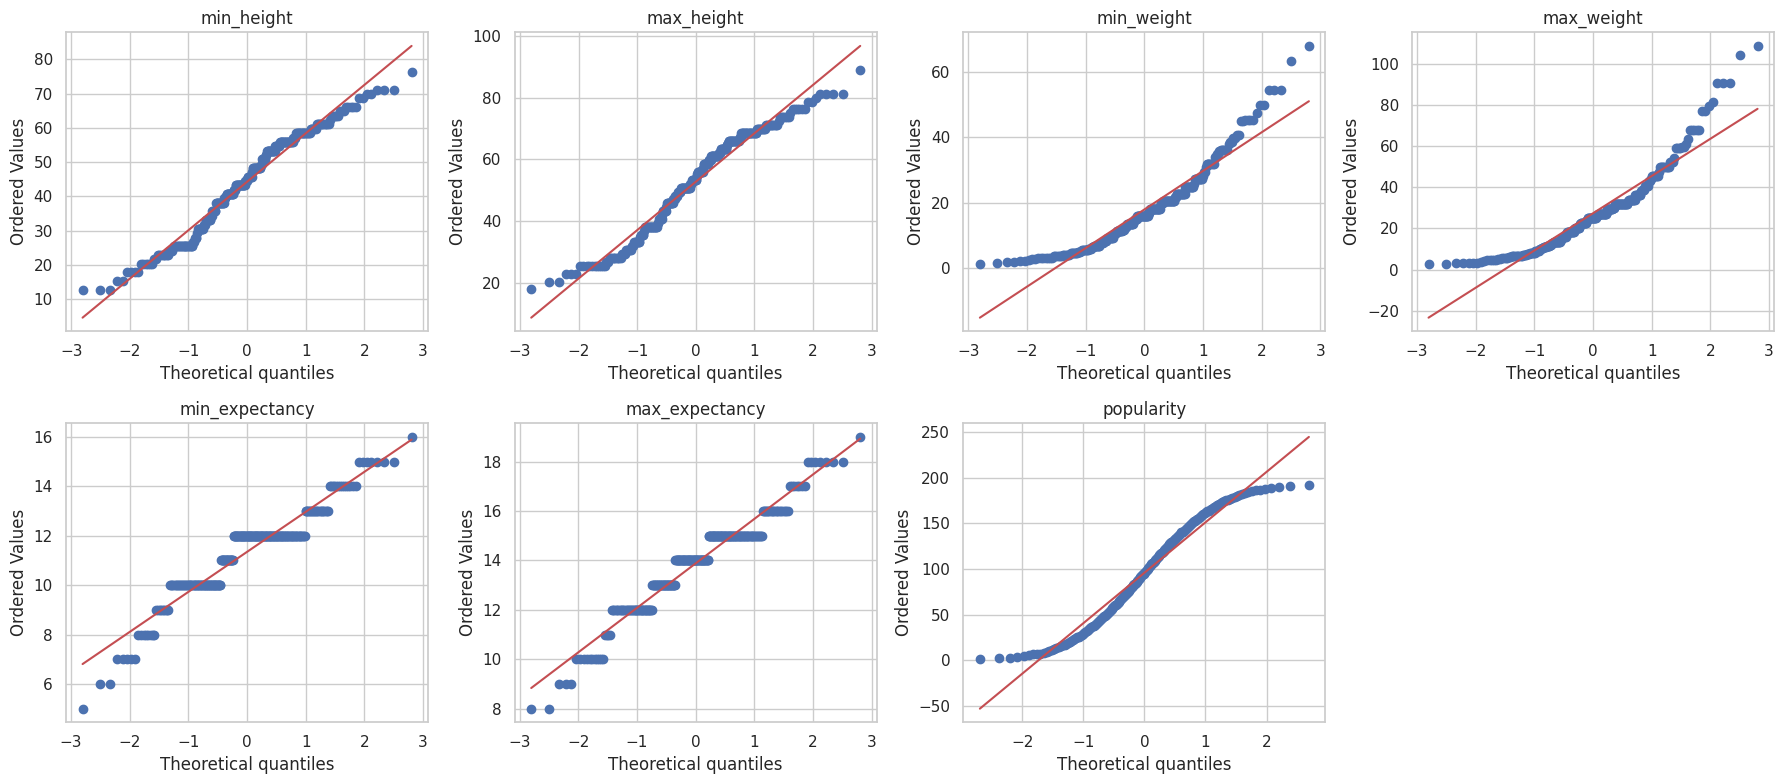

col                 skew  excess_kurt
min_height         -0.23        -0.89
max_height         -0.25        -0.97
min_weight          1.14         1.47
max_weight          1.36         2.51
min_expectancy     -0.55         1.16
max_expectancy     -0.40         0.66
popularity         -0.00        -1.21


In [66]:
from scipy.stats import skew, kurtosis

NUM_COLS = ['min_height','max_height','min_weight','max_weight',
            'min_expectancy','max_expectancy','popularity']

# --- QQ-plots ---
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(NUM_COLS):
    sub = df[col].dropna()
    stats.probplot(sub, dist='norm', plot=axes[i])
    axes[i].set_title(col)
for j in range(i+1, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

# --- Асимметрия и эксцесс ---
print(f'{"col":15s} {"skew":>8s} {"excess_kurt":>12s}')
for col in NUM_COLS:
    s = df[col].dropna()
    print(f'{col:15s} {skew(s):8.2f} {kurtosis(s):12.2f}')

### асимметрия и эксцесс

**Асимметрия** — мера несимметричности распределения относительно
среднего:

$$\text{Skew} = \frac{\frac{1}{n}\sum_{i=1}^{n}(x_i - \bar{x})^3}{\left(\sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_i - \bar{x})^2}\right)^3}$$

- Skew ≈ 0 — симметричное; Skew > 0 — правый хвост длиннее (среднее > меедианы);
  Skew < 0 — левый хвост длиннее (среднее < медаины);
- |Skew| < 0.5 — слабая, 0.5–1 — умеренная, > 1 — сильная асимметрия.

**Эксцесс** — мера тяжести хвостов относительно нормального:

$$\text{Excess Kurt} = \frac{\frac{1}{n}\sum_{i=1}^{n}(x_i - \bar{x})^4}{\left(\frac{1}{n}\sum_{i=1}^{n}(x_i - \bar{x})^2\right)^2} - 3$$

- Excess Kurt ≈ 0 — как у нормального; > 0  — тяжёлые хвосты
  (экстремумы чаще); < 0  — лёгкие хвосты, плоская вершина.


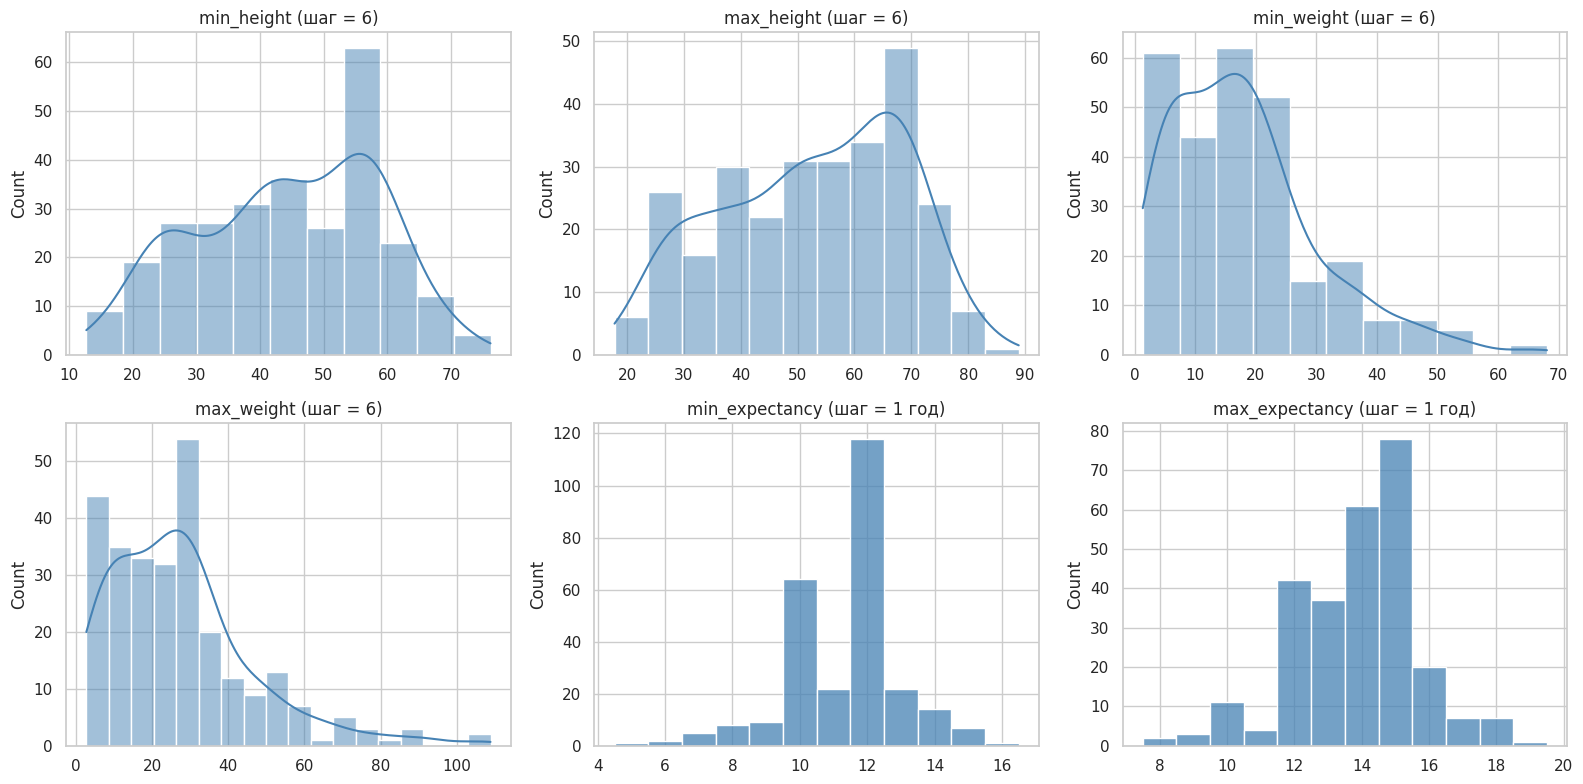

In [67]:

NUM_COLS = ['min_height', 'max_height', 'min_weight', 'max_weight',
            'min_expectancy', 'max_expectancy']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(NUM_COLS):

    if 'expectancy' in col:
        bins_array = np.arange(df[col].min() - 0.5, df[col].max() + 1.5, 1)

        sns.histplot(df[col].dropna(), bins=bins_array, kde=False,
                     ax=axes[i], color='steelblue')
        axes[i].set_title(f'{col} (шаг = 1 год)')

    else:
        step = 6

        sns.histplot(df[col].dropna(), binwidth=step, kde=True,
                     ax=axes[i], color='steelblue')
        axes[i].set_title(f'{col} (шаг = {step})')

    axes[i].set_xlabel('')

plt.tight_layout()
plt.show()

###  Форма распределений (гистограммы)

По гистограммам видно, что распределения **не являются нормальными**,
и каждое имеет свою специфику:

1. **Рост (min_height, max_height) — бимодальность.**
   Видны два четких пика: мелкие породы и крупные. Породы делятся на размерные классы
   , а не распределены непрерывно.

2. **Вес (min_weight, max_weight) — справосторонняя асимметрия.**
   Пик слева (5–15 кг), длинный хвост вправо (до 100+ кг).
   Большинство пород легкие, но есть несколько очень тяжелых,
   которые тянут среднее вверх (mean > median).
   *Следствие:* медиана — более честная мера центра, чем среднее.

3. **Продолжительность жизни (min_expectancy, max_expectancy) — дискретны.**

**Вывод:** гистограммы визуально подтверждают ненормальность распределений,
обнаруженную тестом Шапиро-Уилка.

In [68]:
for c in ['group', 'grooming_frequency_category', 'shedding_category',
          'energy_level_category', 'trainability_category', 'demeanor_category']:
    n_ws = (df[c] != df[c].str.strip()).sum()
    print(f'{c:30s}: строк с пробелами по краям = {n_ws}')

group                         : строк с пробелами по краям = 0
grooming_frequency_category   : строк с пробелами по краям = 7
shedding_category             : строк с пробелами по краям = 20
energy_level_category         : строк с пробелами по краям = 6
trainability_category         : строк с пробелами по краям = 24
demeanor_category             : строк с пробелами по краям = 25
